In [1]:
import gc
import re

In [2]:
import textwrap

import matplotlib
import numpy as np
import xarray as xr
from matplotlib import colors as mcol
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [3]:
from data import (
    _load_single_dataset,
    ds_pressure,
    ds_single,
)

In [4]:
from pathlib import Path

plots = Path("plots")

In [5]:
from compression_recommendations import Recommendations
from compression_recommendations.requirements.abc import Requirement
from compression_recommendations.requirements.combinators import (
    AllRequirements,
    AnyRequirement,
)
from compression_recommendations.requirements.error_bounds.max import (
    MaxPointwiseAbsoluteErrorBoundRequirement,
    MaxPointwiseQuadraticErrorBoundRequirement,
    MaxPointwiseRangeRelativeErrorBoundRequirement,
    MaxPointwiseRelativeErrorBoundRequirement,
)
from compression_recommendations.requirements.error_bounds.mean import (
    MeanAbsoluteErrorBoundRequirement,
    MeanRangeRelativeErrorBoundRequirement,
    MeanRelativeErrorBoundRequirement,
)
from compression_recommendations.requirements.isovalue import IsovalueRequirement
from compression_recommendations.requirements.limits import DataLimitsRequirement
from compression_recommendations.requirements.lossless import LosslessRequirement
from compression_recommendations.requirements.missing import MissingValueRequirement

In [6]:
expert_recommendations = Recommendations.provide

In [7]:
with Path("recommendations", "uncertainty.yaml").open("r") as f:
    uncertainty_recommendations = Recommendations.load(f)

In [8]:
with Path("recommendations", "bit-information.yaml").open("r") as f:
    bit_information_recommendations = Recommendations.load(f)

In [9]:
with Path("recommendations", "grib-linear-packing.yaml").open("r") as f:
    grib_recommendations = Recommendations.load(f)

In [10]:
def plot_uncertainty_mean_spread(
    mean: xr.DataArray,
    spread: xr.DataArray,
    plot: Path,
    extra_markers: dict,
    title_extra: str = "",
):
    mean, spread = mean.copy(deep=True), spread.copy(deep=True)
    meanv, spreadv = mean.values.flatten(), spread.values.flatten()

    arange = np.nanmax(meanv) - np.nanmin(meanv)

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(6.4, 3.6), clear=True)

    m0, m01, m999, m100 = np.nanquantile(meanv, [0.0, 0.001, 0.999, 1.0])
    s99, s100 = np.nanquantile(spreadv, [0.99, 1.0])

    if m01 != m999:
        ms = m999 - m01
        xl, xh = m01 - ms * 0.05, m999 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    elif m100 != m0:
        ms = m100 - m0
        xl, xh = m0 - ms * 0.05, m100 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    else:
        ax.set_xlim(-0.05, 0.05)

    if s99 != 0.0:
        ss = s99
        ax.set_ylim(0.0 - ss * 0.05, s99 + ss * 0.05)
    elif s100 != 0.0:
        ss = s100
        ax.set_ylim(0.0 - ss * 0.05, s100 + ss * 0.05)
    else:
        ax.set_ylim(-0.05, 0.05)

    ax2.set_xlim(*ax.get_xlim())
    ax2.set_ylim(*ax.get_ylim())

    fig.suptitle(
        "\n".join(
            textwrap.wrap(f"{mean.long_name} ({mean.name}){title_extra}", width=45)
        )
    )

    spread_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", spread.units)
    ax.set_ylabel(f"spread [{spread_units}]")

    ax.hist2d(
        meanv,
        spreadv,
        bins=[51, 51],
        range=[ax.get_xlim(), ax.get_ylim()],
        cmap="GnBu",
        norm=mcol.LogNorm(),
    )

    for p, ls in zip(
        ["100.0%", "99.9%", "99.0%", "95.0%"],
        ["-", "-.", "--", ":"],
    ):
        (bit_information_requirement,) = bit_information_recommendations.search(
            markers={
                "cf-short-name": mean.name,
                "tags": f"{p}",
                **extra_markers,
            }
        )
        assert isinstance(
            bit_information_requirement, MaxPointwiseRelativeErrorBoundRequirement
        )
        x = ax.get_xlim()
        x = np.array(sorted(list(x) + [0.0]))
        ax2.plot(
            x,
            np.abs(x) * bit_information_requirement.value,
            ls=ls,
            c="tab:olive",
            lw=2,
            zorder=2,
        )

    uncertainty_bound_legend = []

    for p, pp, ls in zip(
        ["0.0%", "0.1%", "1.0%", "5.0%"],
        ["0%", "0.1%", "1%", "5%"],
        ["-", "-.", "--", ":"],
    ):
        (uncertainty_requirement,) = uncertainty_recommendations.search(
            markers={
                "cf-short-name": mean.name,
                "tags": f"pick,{p}",
                **extra_markers,
            }
        )

        if isinstance(
            uncertainty_requirement, MaxPointwiseAbsoluteErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.linspace(x[0], x[1], num=100)
            el = ax2.plot(
                x,
                [uncertainty_requirement.value] * len(x),
                ls=ls,
                c="tab:blue",
                lw=2,
                markevery=(5, 10),
                marker="s",
                markersize=4,
                zorder=2.5,
                label=rf"{pp}: $\epsilon_{{abs}}$",
            )[0]
            uncertainty_bound_legend.append(
                el
                if pp == "0%"
                else matplotlib.lines.Line2D(
                    [0],
                    [0],
                    ls=ls,
                    c="tab:blue",
                    lw=2,
                    label=rf"{pp}: $\epsilon_{{abs}}$",
                )
            )
        elif isinstance(
            uncertainty_requirement, MaxPointwiseRelativeErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.array(sorted(list(np.linspace(x[0], x[1], num=100)) + [0.0]))
            el = ax2.plot(
                x,
                np.abs(x) * uncertainty_requirement.value,
                ls=ls,
                c="tab:orange",
                lw=2,
                markevery=(5, 10),
                marker="s",
                markersize=4,
                zorder=2.5,
                label=rf"{pp}: $\epsilon_{{rel}}$",
            )[0]
            uncertainty_bound_legend.append(
                el
                if pp == "0%"
                else matplotlib.lines.Line2D(
                    [0],
                    [0],
                    ls=ls,
                    c="tab:orange",
                    lw=2,
                    label=rf"{pp}: $\epsilon_{{rel}}$",
                )
            )
        elif isinstance(
            uncertainty_requirement, MaxPointwiseQuadraticErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.linspace(x[0], x[1], num=100)
            q, mi, ma = (
                uncertainty_requirement.value,
                uncertainty_requirement.minimum,
                uncertainty_requirement.maximum,
            )
            el = ax2.plot(
                x,
                q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi)) ** 2,
                ls=ls,
                c="tab:green",
                lw=2,
                markevery=(5, 10),
                marker="s",
                markersize=4,
                zorder=2.5,
                label=rf"{pp}: $\epsilon_{{qua}}$",
            )[0]
            uncertainty_bound_legend.append(
                el
                if pp == "0%"
                else matplotlib.lines.Line2D(
                    [0],
                    [0],
                    ls=ls,
                    c="tab:green",
                    lw=2,
                    label=rf"{pp}: $\epsilon_{{qua}}$",
                )
            )
        else:
            assert False, repr(uncertainty_requirement)

    (grib_requirement,) = grib_recommendations.search(
        markers={
            "cf-short-name": mean.name,
            **extra_markers,
        }
    )
    assert isinstance(grib_requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
    ax2.axhline(
        grib_requirement.value * arange,
        xmin=-0.025,
        xmax=1.025,
        clip_on=False,
        c="tab:gray",
        lw=1,
        zorder=1.5,
    )

    expert_requirements = expert_recommendations.search(
        markers={
            "cf-short-name": mean.name,
            **extra_markers,
        }
    )

    x = ax.get_xlim()
    x = np.linspace(x[0], x[1], num=101)

    # just compute error bound from absolute and relative requirements
    # for simplicity, maximum and mean requirements are treated the same
    def compute_error_bound(expert_requirement: Requirement) -> None | np.ndarray:
        if isinstance(expert_requirement, AnyRequirement):
            bounds = [
                bound
                for expert_req in expert_requirement.requirements
                if (bound := compute_error_bound(expert_req)) is not None
            ]
            return (
                np.amax(
                    np.stack(
                        bounds,
                        axis=0,
                    ),
                    axis=0,
                )
                if len(bounds) > 0
                else None
            )
        elif isinstance(expert_requirement, AllRequirements):
            bounds = [
                bound
                for expert_req in expert_requirement.requirements
                if (bound := compute_error_bound(expert_req)) is not None
            ]
            return (
                np.amin(
                    np.stack(
                        bounds,
                        axis=0,
                    ),
                    axis=0,
                )
                if len(bounds) > 0
                else None
            )
        elif isinstance(
            expert_requirement,
            MaxPointwiseAbsoluteErrorBoundRequirement
            | MeanAbsoluteErrorBoundRequirement,
        ):
            return np.full_like(x, expert_requirement.value)
        elif isinstance(
            expert_requirement,
            MaxPointwiseRelativeErrorBoundRequirement
            | MeanRelativeErrorBoundRequirement,
        ):
            return np.abs(x) * expert_requirement.value
        elif isinstance(
            expert_requirement,
            MaxPointwiseRangeRelativeErrorBoundRequirement
            | MeanRangeRelativeErrorBoundRequirement,
        ):
            return np.full_like(x, expert_requirement.value * arange)
        elif isinstance(expert_requirement, LosslessRequirement):
            return np.zeros_like(x)
        elif isinstance(expert_requirement, IsovalueRequirement):
            return None  # ignore isovalue
        elif isinstance(expert_requirement, DataLimitsRequirement):
            return None  # ignore data limits
        elif isinstance(expert_requirement, MissingValueRequirement):
            return None  # ignore missing value
        else:
            assert False, f"{expert_requirement.kind}"

    ax2.plot(
        x,
        np.amin(
            np.stack(
                [
                    bound
                    for expert_req in expert_requirements
                    if (bound := compute_error_bound(expert_req)) is not None
                ],
                axis=0,
            ),
            axis=0,
        ),
        ls=":",
        c="black",
        lw=2,
        markevery=(5, 10),
        marker="o",
        markersize=4,
        zorder=2.5,
    )

    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax2.xaxis.set_major_locator(plt.MaxNLocator(4))

    ax2.legend(handles=uncertainty_bound_legend[::-1], loc="upper center", ncols=1)

    divider = make_axes_locatable(ax)

    ax_histx = divider.append_axes("bottom", 0.33, pad=0.15, sharex=ax)
    ax_histx.hist(meanv, bins=51, log=True)
    ax_histx.invert_yaxis()
    mean_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", mean.units)
    ax_histx.set_xlabel(f"mean [{mean_units}]")
    ax.xaxis.set_tick_params(which="both", labelbottom=False)

    ax_histy = divider.append_axes("right", 0.33, pad=0.15, sharey=ax)
    ax_histy.hist(spreadv, bins=51, log=True, orientation="horizontal")
    ax_histy.tick_params(axis="x", labelrotation=45)
    ax_histy.yaxis.set_tick_params(which="both", labelleft=False)

    divider2 = make_axes_locatable(ax2)

    ax2_histx = divider2.append_axes("bottom", 0.33, pad=0.15, sharex=ax2)
    ax2_histx.axis("off")

    ax2.yaxis.set_tick_params(which="both", labelleft=False)

    plt.tight_layout()

    ax.set_title("ERA5 uncertainty", fontsize="medium")
    ax2.set_title("Error bounds", fontsize="medium")

    plot.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot)

    plt.close(fig)

In [11]:
from tqdm import tqdm

In [12]:
for i, key in tqdm(enumerate(sorted(ds_single.mean))):
    if (i > 0) and (i % 30 == 0):
        del ds_single
        gc.collect()
        ds_single = _load_single_dataset()
    plot_uncertainty_mean_spread(
        ds_single.mean[key],
        ds_single.spread[key],
        plots / "single" / f"{key}.pdf",
        extra_markers={"level-kind": "single"},
    )

/var/folders/8v/swxsmn0d4vz5yzwjhf6bc26x3g7lq6/T/ipykernel_50266/2038484667.py:329: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
226it [49:29, 13.14s/it]


In [13]:
for i, key in tqdm(enumerate(sorted(ds_pressure.mean))):
    if (i > 0) and (i % 3 == 0):
        gc.collect()
    for pressure in sorted(ds_pressure.mean[key].pressure_level.values):
        plot_uncertainty_mean_spread(
            ds_pressure.mean[key].sel(pressure_level=pressure),
            ds_pressure.spread[key].sel(pressure_level=pressure),
            plots / "pressure" / f"{key}-{pressure}hPa.pdf",
            extra_markers={"level-kind": "pressure", "level-value": pressure},
            title_extra=f" at {pressure}hPa",
        )

16it [16:21, 61.32s/it]


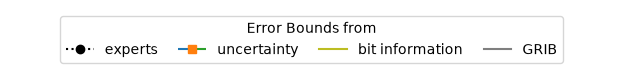

In [14]:
from matplotlib.collections import LineCollection
from matplotlib.legend_handler import HandlerLineCollection

fig, ax = plt.subplots(figsize=(6.4, 0.75), layout="tight")


# adopted from https://stackoverflow.com/a/49224137
class HandlerColorLineCollection(HandlerLineCollection):
    def create_artists(
        self, legend, artist, xdescent, ydescent, width, height, fontsize, trans
    ):
        x = np.linspace(0, width, self.get_numpoints(legend) + 1)
        y = np.zeros(self.get_numpoints(legend) + 1) + height / 2.0 - ydescent
        points = np.array([x, y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        lc = LineCollection(segments, colors=artist.get_colors(), transform=trans)
        lc.set_array(x)
        lc.set_linewidth(artist.get_linewidth())
        return [
            lc,
            matplotlib.lines.Line2D(
                [(x[0] + x[-1]) / 2],
                [(y[0] + y[-1]) / 2],
                ls="-",
                color=(0, 0, 0, 0),
                marker="s",
                markerfacecolor="tab:orange",
                markeredgecolor="tab:orange",
            ),
        ]


lc = matplotlib.collections.LineCollection(
    [],
    colors=["tab:blue", "tab:orange", "tab:green"],
    label="uncertainty",
)

ax.legend(
    handles=[
        matplotlib.lines.Line2D(
            [0], [0], ls=":", color="black", marker="o", label="experts"
        ),
        lc,
        matplotlib.lines.Line2D([0], [0], color="tab:olive", label="bit information"),
        matplotlib.lines.Line2D([0], [0], color="tab:gray", label="GRIB"),
    ],
    loc="upper center",
    ncols=4,
    columnspacing=1.5,
    title="Error Bounds from",
    handler_map={lc: HandlerColorLineCollection(numpoints=3)},
)

ax.set_axis_off()

plt.show()
fig.savefig(plots / "legend.pdf")